In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

X
(100, 1)
y
(100, 1)


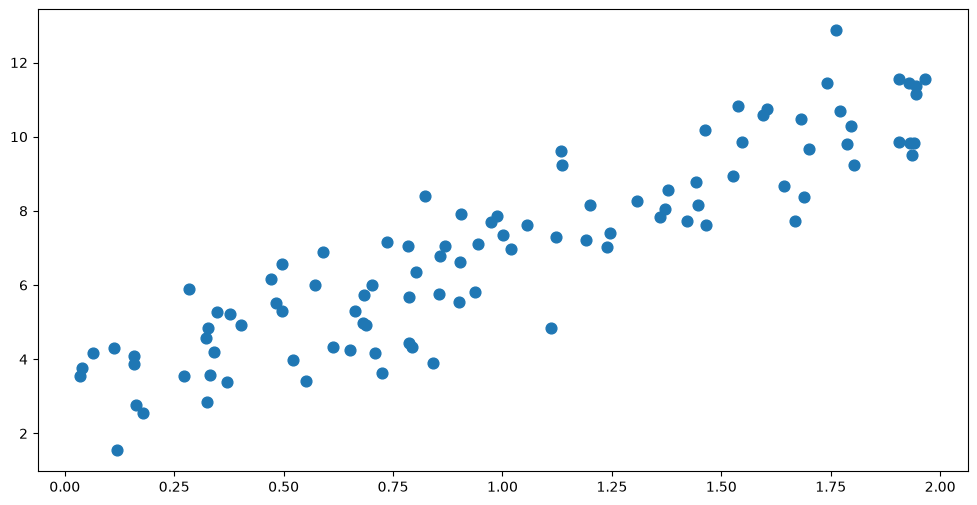

In [15]:
np.random.seed(33)

# Generaremos daos lineales con ruido
X = 2 * np.random.rand(100, 1)
y = 4 * X +3 + np.random.randn(100, 1)
print("X")
print(X.shape)
print("y")
print(y.shape)

# Visualizacion
plt.figure(figsize=(12,6))
plt.scatter(X, y, s=60, label="Datos")

In [19]:
# Definimos la función de coste MSE
def compute_cost(X, y, beta):
    n = len(y)
    y_pred = X @ beta
    error = y - y_pred
    cost = (1 / n) * np.sum(error**2)
    return cost

# Preparamos X con columna de 1s (intercepto)
X1 = sm.add_constant(X)  # añade columna de 1s
beta_inicial = np.zeros((2, 1))    # matriz de coeficientes: beta_0 = 0, beta_1 = 0

coste_inicial = compute_cost(X1, y, beta_inicial)
print("Coste inicial (beta_0=0, beta_1=0):", coste_inicial)


Coste inicial (beta_0=0, beta_1=0): 54.97090132216898


In [21]:
def compute_gradient(X, y, beta):
    n = len(y)
    gradient = (1 / n) * X.T @ (X @ beta - y)
    return gradient

# Gradiente con beta inicial (0,0)
gradiente_inicial = compute_gradient(X1, y, beta_inicial)
print("Gradiente inicial: ", gradiente_inicial.ravel())

def gradient_descent(X, y, beta_inicial, learning_rate, n_iter):
    beta = beta_inicial.copy()
    history = []

    for _ in range(n_iter):
        grad = compute_gradient(X, y, beta)
        beta -= learning_rate * grad
        history.append(compute_cost(X, y, beta))

    return beta, history

# ejecutamos el descenso de gradiente
beta_final, history = gradient_descent(X1, y, beta_inicial, learning_rate=0.1, n_iter=100)

print("Coeficientes finales:")
print("Intercepto (beta_0):", beta_final[0][0])
print("Pendiente (beta_1):", beta_final[1][0])

Gradiente inicial:  [-6.95739967 -8.26540396]
Coeficientes finales:
Intercepto (beta_0): 2.9591151363876698
Pendiente (beta_1): 4.014790483979907


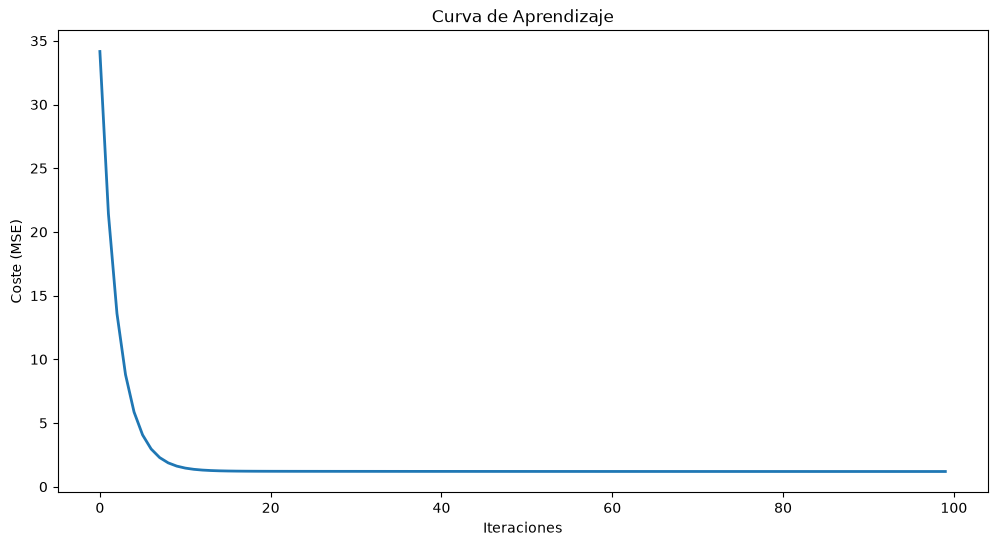

In [22]:
plt.figure(figsize=(12, 6))
plt.plot(history, lw=2)
plt.xlabel("Iteraciones")
plt.ylabel("Coste (MSE)")
plt.title("Curva de Aprendizaje")
plt.show()

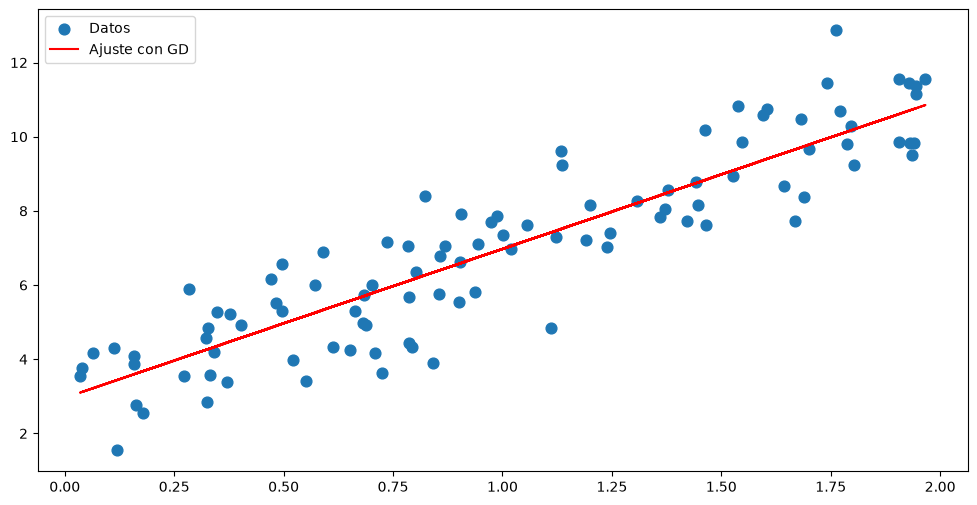

In [28]:
# Predicciones usando los parametros finales
y_pred = X1 @beta_final

# Visualizacion
plt.figure(figsize=(12,6))
plt.scatter(X, y, s=60, label="Datos")
plt.plot(X, y_pred, color="red", label="Ajuste con GD")
plt.legend()